# Introduction to pandapower 

pandapower is an open‑source Python library for power system modelling and analysis. It stores information about a network and provides the functionality for running power-flow calculations, plotting, geospatial interpretability and saving that data. As the name suggests it is built on pandas with the network and power-flow results being stored within pandas dataframes.

This is a very scaled down introduction to *pandapower* where we load in a JSON file using *pandapower* and use our previous knowledge of Pandas to explore and plot the data.

You can access good 'Getting Started' examples and the documentation via the [pandapower website](https://www.pandapower.org/start/)

### Import libraries

In [1]:
# Import Pandas and pandapower below. Be sure to import them correctly
import pandapower as pp

## Networks
In pandapower, the Network object is the central container for a power system model. It stores network elements (buses, lines, loads, generators, switches, - more on this next week) as pandas DataFrames and holds power-flow results in matching res_ DataFrames after you run a power flow.

Networks can be built from scratch using the pandapower.create_* functions, but for ease, lets import a pre-made one.

### 1. Import the example network saved in 'ThreeBusPlot23.json'. Be sure to add the right path for your file!

In [3]:
# Use pandapower to load the file called "ThreeBusPlot25.json" and assign to a variable called 'net'
net = pp.from_json("../Data/ThreeBusPlot25.json")

### 2. Executing simply net will provide you with some details of what is contained within the network.

In [4]:
# calling the network object provides some details of its structure
net

This pandapower network includes the following parameter tables:
   - bus (3 elements)
   - load (2 elements)
   - ext_grid (1 element)
   - line (3 elements)

### 3. Print the object type of the 'line' attribute of 'net'.


In [5]:
# print the object type of the line attribute of net
print(net.line.__class__)

<class 'pandas.core.frame.DataFrame'>


As you can see, under the hood, pandapower uses Dataframes. 

**Call net.line to view the dataframe and its contents.**

In [6]:
net.line

,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,geo
0,None,None,0,1,484.0,0.0200,0.040,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.2763, 51.7503], [-1.189, 5..."
1,None,None,1,2,484.0,0.0125,0.025,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.189, 51.7236], [-1.3269, 5..."
2,None,None,2,0,484.0,0.0100,0.030,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.3269, 51.6312], [-1.2763, ..."


### 4. Now run a power flow on the network using the pandapower.runpp function

In [7]:
# run a power flow on the network using the pandapower runpp function 
pp.runpp(net)

### 5. Explore the underlying data that contains the power flow results

In [15]:
# Set some Dataframe variables up (called: 'df1', 'df2' and 'df3') so that they can be respectively 
# assigned to the 'line' and 'res_line'
df1 = net.line
df2 = net.res_line
df3 = net.line.copy()

In [19]:
# explore the contents of the dataframes
df1.head()
df2.head()


,p_from_mw,q_from_mvar,p_to_mw,q_to_mvar,pl_mw,ql_mvar,i_from_ka,i_to_ka,i_ka,vm_from_pu,va_from_degree,vm_to_pu,va_to_degree,loading_percent
0,199.5,84.0,-191.0,-67.0,8.5,17.0,0.541017,0.541017,0.541017,1.050000,0.000000,0.981835,-3.503532,0.054102
1,-65.6,-43.2,66.4,44.8,0.8,1.6,0.209946,0.209946,0.209946,0.981835,-3.503532,1.001249,-2.862405,0.020995
2,-205.0,-90.0,210.0,105.0,5.0,15.0,0.586816,0.586816,0.586816,1.001249,-2.862405,1.050000,0.000000,0.058682


In [23]:
# In df1, change the value of 'r_ohm_per_km' from 0.0125 to 0.07. This must be done in only one line.
# Once done, check to see if the change has been made.
df1.loc[0, 'r_ohm_per_km'] = 0.07
df1.head()

,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,geo
0,None,None,0,1,484.0,0.0700,0.040,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.2763, 51.7503], [-1.189, 5..."
1,None,None,1,2,484.0,0.0125,0.025,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.189, 51.7236], [-1.3269, 5..."
2,None,None,2,0,484.0,0.0100,0.030,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.3269, 51.6312], [-1.2763, ..."


In [24]:
# Show that the change in 'df1' ALSO changes 'net.line' - Why would this happen?
display(df1.head())
display(net.line.head())

# direct checks
print(net.line.loc[1, "r_ohm_per_km"])   # 0.07, even though we only edited df1
print(df1 is net.line)                   # True: they are the same object


,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,geo
0,None,None,0,1,484.0,0.0700,0.040,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.2763, 51.7503], [-1.189, 5..."
1,None,None,1,2,484.0,0.0125,0.025,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.189, 51.7236], [-1.3269, 5..."
2,None,None,2,0,484.0,0.0100,0.030,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.3269, 51.6312], [-1.2763, ..."


,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,geo
0,None,None,0,1,484.0,0.0700,0.040,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.2763, 51.7503], [-1.189, 5..."
1,None,None,1,2,484.0,0.0125,0.025,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.189, 51.7236], [-1.3269, 5..."
2,None,None,2,0,484.0,0.0100,0.030,1.000000e-09,0.0,1000.0,1.0,1,None,True,"{""coordinates"":[[-1.3269, 51.6312], [-1.2763, ..."


0.0125
True


### 6. Rerun the power flow on the updated network. Does anything change in the net.res_line?

In [25]:
# Rerun the power flow on the updated network. Does anything change in the net.res_line?
pp.runpp(net)
df2.head()


,p_from_mw,q_from_mvar,p_to_mw,q_to_mvar,pl_mw,ql_mvar,i_from_ka,i_to_ka,i_ka,vm_from_pu,va_from_degree,vm_to_pu,va_to_degree,loading_percent
0,199.5,84.0,-191.0,-67.0,8.5,17.0,0.541017,0.541017,0.541017,1.050000,0.000000,0.981835,-3.503532,0.054102
1,-65.6,-43.2,66.4,44.8,0.8,1.6,0.209946,0.209946,0.209946,0.981835,-3.503532,1.001249,-2.862405,0.020995
2,-205.0,-90.0,210.0,105.0,5.0,15.0,0.586816,0.586816,0.586816,1.001249,-2.862405,1.050000,0.000000,0.058682


## Plotting

### 7. From the pandapower.plotting module, import the simple_plotting convenience function and use it to plot the network.

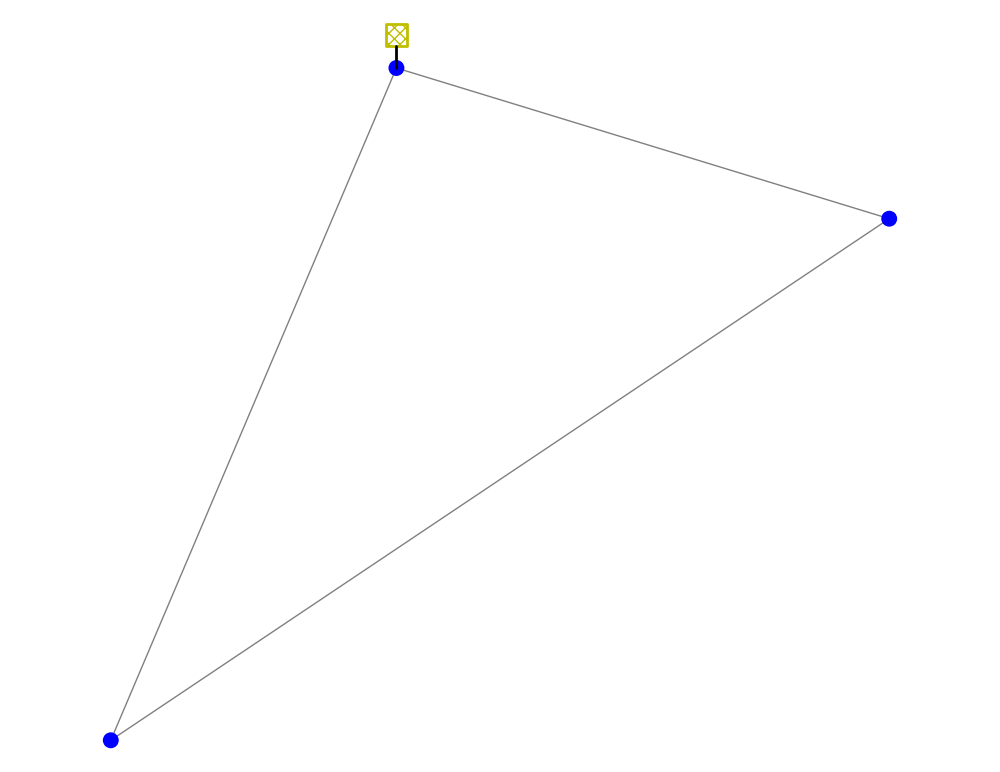

<Axes: >

In [27]:
# plot the network using the pandapower convenience function
from pandapower.plotting import simple_plot
simple_plot(net)

For more examples of basic plotting, take a look at the basic [plotting tutorial](https://github.com/e2nIEE/pandapower/blob/master/tutorials/plotting_basic.ipynb).

### 8. With reference to [pandapower colormap tutorial](https://github.com/e2nIEE/pandapower/blob/master/tutorials/plotting_colormaps.ipynb), trying plotting a color map highlighting the line loadings for the 3 bus network. Check the lines dataframe to identify a color ranges that will highlight the different line loadings for this particular network loading.

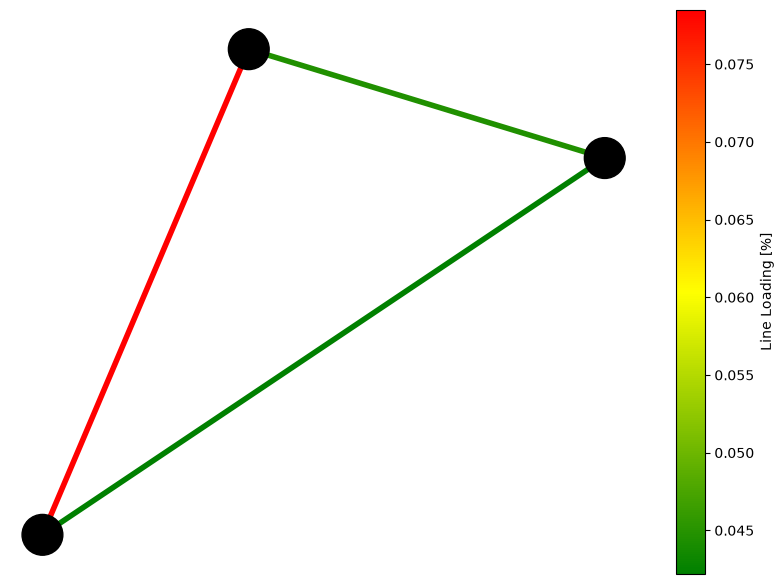

In [28]:
# use collections to plot a colourmap showing line loadings
import matplotlib.pyplot as plt
import pandapower.plotting as plot

# 1. Find the lowest and highest line loading in the results
lmin = net.res_line["loading_percent"].min()
lmax = net.res_line["loading_percent"].max()

# 2. Make a colour scale: green = lowest loading, yellow = middle, red = highest
cmap, norm = plot.cmap_continuous([(lmin, "green"),
                                   ((lmin + lmax) / 2, "yellow"),
                                   (lmax, "red")])

# 3. Make the "drawing pieces"
line_coll = plot.create_line_collection(net, net.line.index, cmap=cmap, norm=norm,
                                        linewidths=4, zorder=1, use_bus_geodata=False)
bus_coll = plot.create_bus_collection(net, net.bus.index, size=0.005,
                                      color="black", zorder=2)

# 4. Draw all the pieces together
plot.draw_collections([line_coll, bus_coll], figsize=(8, 6))
plt.show()


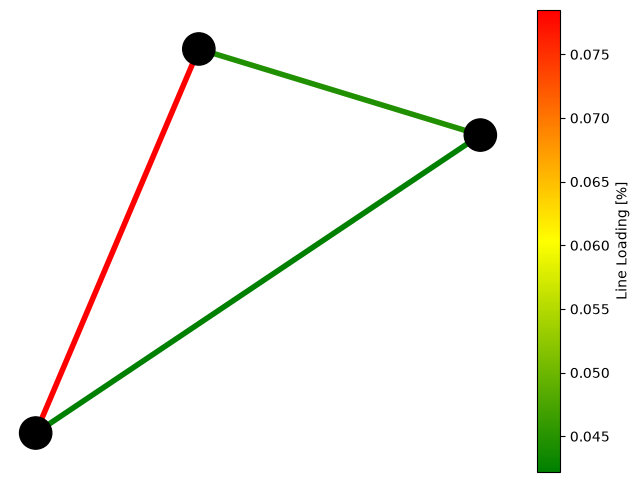

In [30]:
# plot the same figure on a matplotlib figure making use of the ax keyword within the draw_collections function.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
plot.draw_collections([line_coll, bus_coll], ax=ax)
plt.show()


### 9. Try adding a basemap to your plot. There are many ways in which you could do this, one library that makes this particularly helpful is contextily. Use the contextily.add_basemap function to add a basemap to your previous plot.

Note: The coordinates within the network is gcs epsg:4326, e.g. lat long

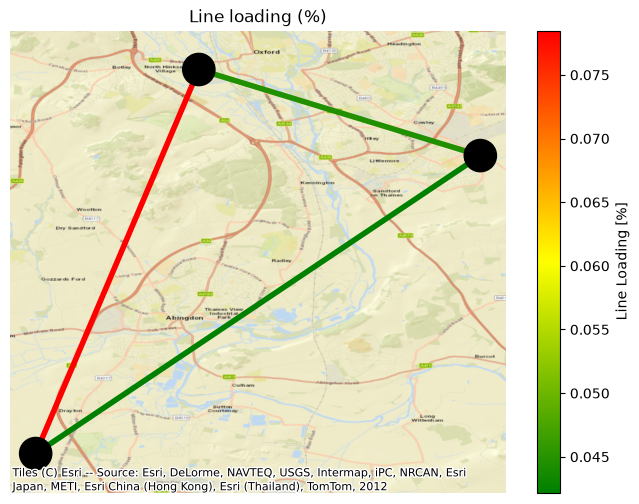

In [31]:
# add a basemap to your plot
import contextily as cx
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
plot.draw_collections([line_coll, bus_coll], ax=ax)   # draw the network first

cx.add_basemap(ax, crs="EPSG:4326", source=cx.providers.Esri.WorldStreetMap)
ax.set_title("Line loading (%)")
plt.show()

For more geospatial analysis options, you might want to convert your pandapower dataframes into a geopandas dataframe.

### 10. Create a GeoDataFrame from the bus and bus_geodata dataframes. Your GDF should have a 'geometry' column containing Point objects and have a crs assigned.

In [33]:
# create a GeoDataFrame
import geopandas as gpd
import pandapower.plotting as pp_plot

bus_geojson = pp_plot.geo.dump_to_geojson(net, nodes=True)
bus_gdf = gpd.GeoDataFrame.from_features(bus_geojson["features"], crs="EPSG:4326")

lines_geojson = pp_plot.geo.dump_to_geojson(net, branches=True)
lines_gdf = gpd.GeoDataFrame.from_features(lines_geojson["features"], crs="EPSG:4326")

bus_gdf


,geometry,name,vn_kv,type,zone,in_service,pp_type,pp_index,vm_pu,va_degree,p_mw,q_mvar
0,POINT (-1.2763 51.7503),Bus 1,220.0,b,None,True,bus,0,1.050000,0.000000,-427.593913,-200.24773
1,POINT (-1.189 51.7236),Bus 2,220.0,b,None,True,bus,1,0.929648,-3.799029,256.600000,110.20000
2,POINT (-1.3269 51.6312),Bus 3,220.0,b,None,True,bus,2,0.973179,-3.126780,138.600000,45.20000


## Timeseries
So far, the power flow has been solved for a single timestamp. How might you go about solving for a timeseries of load and generation?

### 11. Write some pseudo code for a general structure of how you could achieve it.

PandaPower has some built in functions that simplify this for you. Take a look at the [timeseries tutorial](https://github.com/e2nIEE/pandapower/blob/develop/tutorials/time_series.ipynb) if you want more information.

<Axes: xlabel='Hour', ylabel='Line loading (%)'>

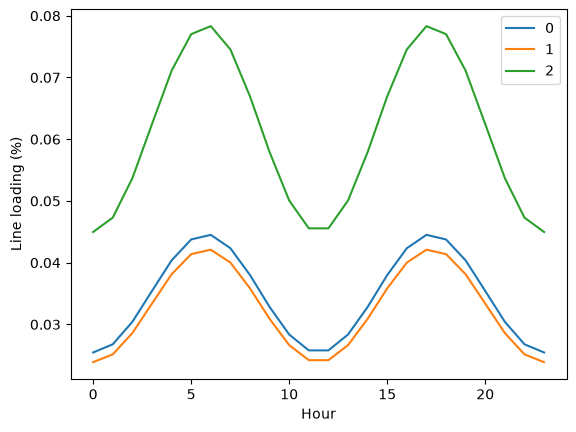

In [34]:
import numpy as np
import pandas as pd

# 2. a made-up daily profile: scaling factor between 0.6 and 1.0 for 24 hours
profile = 0.6 + 0.4 * np.sin(np.linspace(0, 2 * np.pi, 24)) ** 2

# 3. save the original loads
base_p = net.load["p_mw"].copy()
base_q = net.load["q_mvar"].copy()

# 4. somewhere to store results
results = []

# 5. loop over every hour
for hour, scale in enumerate(profile):
    net.load["p_mw"] = base_p * scale       # a. update loads
    net.load["q_mvar"] = base_q * scale
    pp.runpp(net)                           # c. run power flow
    loading = net.res_line["loading_percent"].copy()   # e. store results
    loading.name = hour
    results.append(loading)

# 6. put the loads back
net.load["p_mw"] = base_p
net.load["q_mvar"] = base_q

# 7. results table: one row per hour, one column per line
line_loading = pd.DataFrame(results)
line_loading.index.name = "hour"
line_loading.plot(xlabel="Hour", ylabel="Line loading (%)")
